# PCA Qualitative Analysis

**Purpose:** Unsupervised exploration of the preprocessed spectra with PCA (manuscript Section 4.1, Fig. 2 and Fig. S1). It shows how culture age, species and benzoate condition structure the data, and produces the growth-curve + PC2 loading + PCA scatter composite used as Fig. 2.

**Input:**
- `Preprocessed_Raman_Spectra_2025.pkl` (from `Data_Preprocessing_Pipeline.ipynb`)
- `OD_data.pkl` (OD$_{600}$ growth curves for the two species at 0 and 20 mM benzoate)

**Output:** `Paper and SI images/Figure_S1.svg` (PC1/PC2 loadings) and `Paper and SI images/Figure_2.svg`.

**Method:** each wavenumber is z-scored across all 360 spectra and PCA is fit on the full dataset. This global PCA is for visualisation only; it was *not* used to train or evaluate any classifier (those notebooks refit the scaler and PCA inside every cross-validation fold). It was also used to choose the range of PC numbers (6-92) searched during tuning, which covers 85-99 % of the variance (manuscript Section 3.2).

**Label codes:** `PP` = *P. putida*, `CBG` = *C. glutamicum*; `A` = 0 mM, `C` = 20 mM benzoate; ages 5, 24, 48 h.

**Sections:** load data -> global PCA -> scatter plots grouped by species/condition/age -> loadings and explained variance -> OD curves -> final figure.

In [1]:
# Imports. pd.DataFrame.iteritems is re-added as an alias of .items so that plotly works with newer pandas versions.
# Unused here: KernelPCA, TSNE, plotly, scipy.signal, 3D plotting.
import pandas as pd
pd.DataFrame.iteritems = pd.DataFrame.items
import numpy as np
import os
import re
import pickle

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits import mplot3d
import matplotlib.ticker as mticker
import matplotlib.transforms as transforms
import matplotlib.patches as patches
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec

import plotly.express as px

import scipy
from scipy import signal

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE

In [2]:
# Load the preprocessed dataset (360 spectra x 1003 wavenumbers)
filename = "Preprocessed_Raman_Spectra_2025.pkl"
with open(filename, "rb") as f:
    loaded_data = pickle.load(f)
    
print(loaded_data['Spectra'].shape)

(360, 1003)


In [3]:
# Show the preprocessing settings stored with the data (order SI -> CS -> BSR -> SG -> ED and their parameters)
loaded_data["Preprocess conditions"]

{'order': 'SI --> CS --> BSR --> SG --> ED',
 'CS': [1, 0.01],
 'BSR': [100, 1],
 'SG': [15, 2],
 'ED': [400, 1800]}

In [4]:
# List the dictionary entries (Spectra, wavenumber, species label, culture age, culture condition, replicates, Preprocess conditions)
loaded_data.keys()

dict_keys(['Spectra', 'wavenumber', 'species label', 'culture age', 'culture condition', 'biological replicate', 'technical replicate', 'Preprocess conditions'])

In [5]:
# Unpack the dictionary into separate arrays
wavenumber = np.array(loaded_data["wavenumber"], dtype = np.float64)
spectral = loaded_data["Spectra"]
bacteria_species = loaded_data["species label"]
culture_age = loaded_data['culture age']
cul_cond = loaded_data["culture condition"]
biological_rep = loaded_data["biological replicate"]
technical_rep = loaded_data["technical replicate"]

In [6]:
# Translate the condition codes into readable labels: A = 0 mM benzoate, C = 20 mM benzoate
condition_dict = {"A" : "0 mM benzoate", "C" : "20 mM benzoate"}
culture_condition = []
for i in range(len(cul_cond)):
    culture_condition.append(condition_dict[cul_cond[i]])
culture_condition = np.array(culture_condition)

# Linear PCA transformation

In [7]:
# Exploratory PCA on the full dataset.
# 1) z-score every wavenumber across all spectra (zero mean, unit variance)
# 2) fit PCA with all components and project the spectra onto them (rows = spectra, columns = PC scores)
SS_overall = StandardScaler().fit_transform(spectral)
PCA_overall = PCA()

spectral_pca = PCA_overall.fit_transform(SS_overall)

## Overall PCA time visuvalization by group

In [8]:
# Boolean masks that select each species x condition group (P. putida / C. glutamicum at 0 / 20 mM benzoate).
# Each mask is the AND of two conditions (the two booleans sum to 2) followed by a sanity assert.
inds_P_A = np.array(bacteria_species == "PP", dtype = np.float64) +  np.array(cul_cond == "A", dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_P_A]) == "PP" and np.all(cul_cond[inds_P_A]) == "A" )

inds_P_C = np.array(bacteria_species == "PP", dtype = np.float64) +  np.array(cul_cond == "C", dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_P_C]) == "PP" and np.all(cul_cond[inds_P_C]) == "C" )

inds_C_A = np.array(bacteria_species == "CBG", dtype = np.float64) +  np.array(cul_cond == "A", dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_C_A]) == "CBG" and np.all(cul_cond[inds_C_A]) == "A" )

inds_C_C = np.array(bacteria_species == "CBG", dtype = np.float64) +  np.array(cul_cond == "C", dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_C_C]) == "CBG" and np.all(cul_cond[inds_C_C]) == "C" )

In [9]:
# Draw a confidence ellipse of a 2-D point cloud (x, y) on axis ax.
# Standard matplotlib 'confidence ellipse' recipe: a unit ellipse whose radii are sqrt(1 +/- Pearson r) is rotated by 45 degrees,
# scaled by n_std standard deviations along x and y, and translated to the mean of the points.
# n_std = 2.0 draws the ellipse at two standard deviations.
def confidence_ellipse_cm(x, y, ax, n_std=2.0, facecolor='none', edgecolor='black', **kwargs):
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)

    ellipse = patches.Ellipse((0, 0),
                               width=ell_radius_x * 2,
                               height=ell_radius_y * 2,
                               facecolor=facecolor,
                               edgecolor=edgecolor,
                               **kwargs)

    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_x = np.mean(x)
    mean_y = np.mean(y)

    transf = transforms.Affine2D().rotate_deg(45).scale(scale_x, scale_y).translate(mean_x, mean_y)
    ellipse.set_transform(transf + ax.transData)
    ax.add_patch(ellipse)

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_24936\634389561.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('viridis')


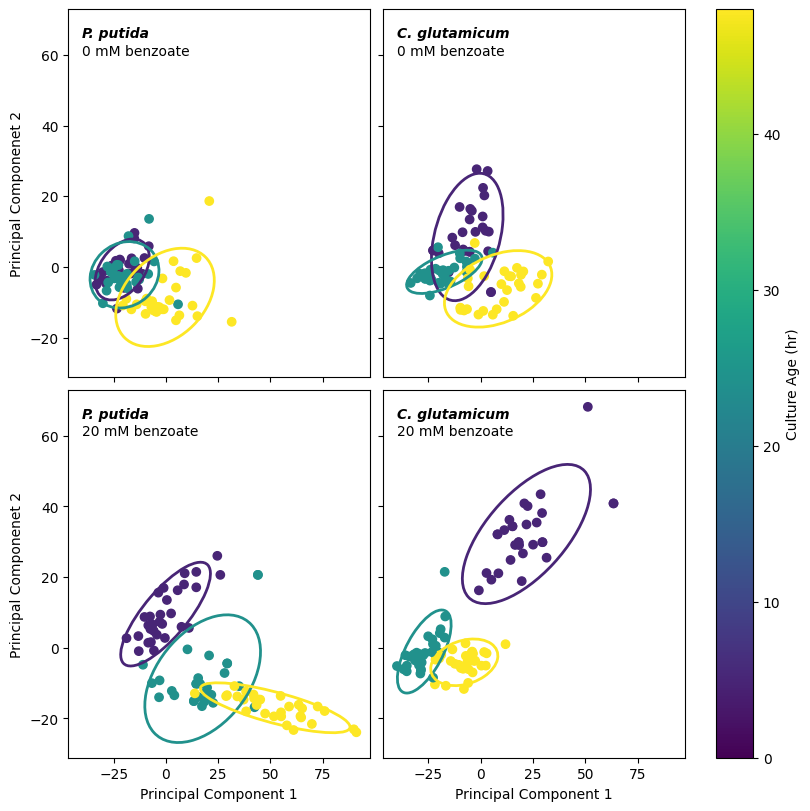

In [10]:
# Fig. 2b: PC1 vs PC2 scatter, one panel per species x condition, points coloured by culture age (viridis),
# with a 2-standard-deviation ellipse around each age group.
fig, axs = plt.subplots(2, 2, figsize = (8, 8), sharex = True, sharey = True, constrained_layout = True)
ax = axs.ravel()

inds_list = [inds_P_A, inds_C_A, inds_P_C, inds_C_C]
spec_name = ["P. putida", "C. glutamicum"]
cond_name = ["0 mM benzoate", "20 mM benzoate"]

for i in range(len(inds_list)):
    
    if i >= 2:
        ax[i].set_xlabel("Principal Component 1")
    if i%2 == 0:
        ax[i].set_ylabel('Principal Componenet 2')
    
    # Scores of this group on PC1/PC2 and its culture ages
    X_p = spectral_pca[inds_list[i], :]
    y = culture_age[inds_list[i]]
    
    # viridis colour scale from 0 to the maximum age (48 h)
    cmap = cm.get_cmap('viridis')
    norm = plt.Normalize(vmin=0, vmax=max(y))
    
    # Annotate the panel with species (italic) and condition
    ax[i].text(-40, 65, spec_name[int(i%2)], fontsize = 10, color = "k", fontstyle = "italic", fontweight = "bold")
    ax[i].text(-40, 60, cond_name[int(i/2)], fontsize = 10, color = "k")   

    sc = ax[i].scatter(X_p[:, 0], X_p[:, 1], c=y, cmap=cmap, norm = norm)
    unique_targets = np.unique(y)
    for target in unique_targets:
        group = X_p[y == target]
        color = cmap(norm(target))
        confidence_ellipse_cm(group[:, 0], group[:, 1], ax[i], n_std=2.0, edgecolor=color, linewidth=2)
        
        
# Shared colorbar for culture age
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation="vertical")#, label="Culture age (hr)")#, 
cbar.set_label("Culture Age (hr)")#, size = 12)

## Overall PCA species visuvalization by group

In [11]:
# Boolean masks that select each species x culture age group (5, 24, 48 h) for the species/condition comparison below
inds_P_5 = np.array(bacteria_species == "PP", dtype = np.float64) +  np.array(culture_age == 5, dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_P_5]) == "PP" and len(np.unique(np.all(culture_age[inds_P_5]))) == 1)

inds_P_24 = np.array(bacteria_species == "PP", dtype = np.float64) +  np.array(culture_age == 24, dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_P_24]) == "PP" and len(np.unique(np.all(culture_age[inds_P_24]))) == 1)

inds_P_48 = np.array(bacteria_species == "PP", dtype = np.float64) +  np.array(culture_age == 48, dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_P_48]) == "PP" and len(np.unique(np.all(culture_age[inds_P_48]))) == 1)

inds_C_5 = np.array(bacteria_species == "CBG", dtype = np.float64) +  np.array(culture_age == 5, dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_C_5]) == "CBG" and len(np.unique(np.all(culture_age[inds_C_5]))) == 1)

inds_C_24 = np.array(bacteria_species == "CBG", dtype = np.float64) +  np.array(culture_age == 24, dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_C_24]) == "CBG" and len(np.unique(np.all(culture_age[inds_C_24]))) == 1)

inds_C_48 = np.array(bacteria_species == "CBG", dtype = np.float64) +  np.array(culture_age == 48, dtype = np.float64) == 2
assert(np.all(bacteria_species[inds_C_48]) == "CBG" and len(np.unique(np.all(culture_age[inds_C_48]))) == 1)

In [12]:
# Draw a confidence ellipse of a 2-D point cloud (x, y) on axis ax.
# Standard matplotlib 'confidence ellipse' recipe: a unit ellipse whose radii are sqrt(1 +/- Pearson r) is rotated by 45 degrees,
# scaled by n_std standard deviations along x and y, and translated to the mean of the points.
# n_std = 2.0 draws the ellipse at two standard deviations.
# This version also accepts a legend label and returns the ellipse.
def confidence_ellipse_cm(x, y, ax, n_std=2.0,
                          facecolor='none', edgecolor='black',
                          label=None, **kwargs):
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)

    ellipse = patches.Ellipse(
        (0, 0),
        width=ell_radius_x * 2,
        height=ell_radius_y * 2,
        facecolor=facecolor,
        edgecolor=edgecolor,
        label=label,          # ← legend label
        **kwargs
    )

    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_x = np.mean(x)
    mean_y = np.mean(y)

    transf = (
        transforms.Affine2D()
        .rotate_deg(45)
        .scale(scale_x, scale_y)
        .translate(mean_x, mean_y)
    )

    ellipse.set_transform(transf + ax.transData)
    ax.add_patch(ellipse)

    return ellipse            # ← return artist for legend handling


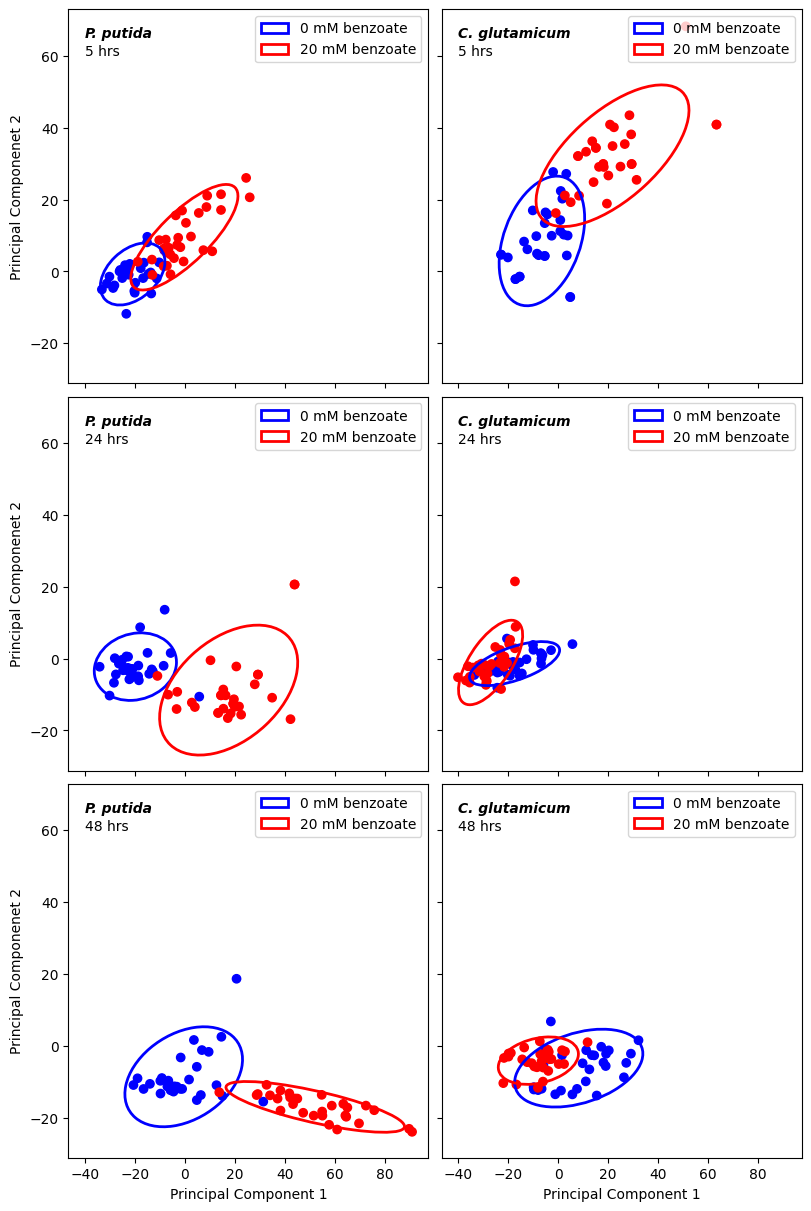

In [13]:
# PC1 vs PC2 for each species x age; points coloured by benzoate condition (blue = 0 mM, red = 20 mM)
# with an ellipse per condition. Shows whether benzoate separates in the leading PCs.
fig, axs = plt.subplots(3, 2, figsize = (8, 12), sharex = True, sharey = True, constrained_layout = True)
ax = axs.ravel()

inds_list = [inds_P_5, inds_C_5, inds_P_24, inds_C_24, inds_P_48, inds_C_48]
spec_name = ["P. putida", "C. glutamicum"]
age_name = ["5 hrs", "24 hrs", "48 hrs"]

for i in range(len(inds_list)):
    
    if i >= 4:
        ax[i].set_xlabel("Principal Component 1")
    if i%2 == 0:
        ax[i].set_ylabel('Principal Componenet 2')
    
    X_p = spectral_pca[inds_list[i], :]
    y = culture_condition[inds_list[i]]
    
    # Colour each point by condition: 20 mM = red, 0 mM = blue
    clist = []
    for j in y:
        if "20 mM" in j:
            clist.append("red")
        else:
            clist.append("blue")
    
    ax[i].text(-40, 65, spec_name[int(i%2)], fontsize = 10, color = "k", fontstyle = "italic", fontweight = "bold")
    ax[i].text(-40, 60, age_name[int(i/2)], fontsize = 10, color = "k")
   
    cdict = {"0 mM benzoate": "blue", "20 mM benzoate" : "red"}
    
    sc = ax[i].scatter(X_p[:, 0], X_p[:, 1], c=clist)
    unique_targets = np.unique(y)
    for target in unique_targets:
        group = X_p[y == target]
        color = cdict[target]
        confidence_ellipse_cm(group[:, 0], group[:, 1], ax[i], n_std=2.0, edgecolor=color, linewidth=2, label = target)
        
    if i == 1:
        loc = "upper right"
    else:
        loc = "best"
    ax[i].legend(loc = loc)

## Overall PCA species visuvalization by group

In [14]:
# Boolean masks that select each culture age x condition group (note: the cell title says 'species visualization', but these groups
# are used to colour points by species)
inds_5_A = np.array(culture_age == 5, dtype = np.float64) +  np.array(cul_cond == "A", dtype = np.float64) == 2
assert(len(np.unique(culture_age[inds_5_A])) == 1 and np.all(cul_cond[inds_5_A]) == "A")

inds_24_A = np.array(culture_age == 24, dtype = np.float64) +  np.array(cul_cond == "A", dtype = np.float64) == 2
assert(len(np.unique(culture_age[inds_24_A])) == 1 and np.all(cul_cond[inds_24_A]) == "A")

inds_48_A = np.array(culture_age == 48, dtype = np.float64) +  np.array(cul_cond == "A", dtype = np.float64) == 2
assert(len(np.unique(culture_age[inds_48_A])) == 1 and np.all(cul_cond[inds_48_A]) == "A")

inds_5_C = np.array(culture_age == 5, dtype = np.float64) +  np.array(cul_cond == "C", dtype = np.float64) == 2
assert(len(np.unique(culture_age[inds_5_C])) == 1 and np.all(cul_cond[inds_5_C]) == "C")

inds_24_C = np.array(culture_age == 24, dtype = np.float64) +  np.array(cul_cond == "C", dtype = np.float64) == 2
assert(len(np.unique(culture_age[inds_24_C])) == 1 and np.all(cul_cond[inds_24_C]) == "C")

inds_48_C = np.array(culture_age == 48, dtype = np.float64) +  np.array(cul_cond == "C", dtype = np.float64) == 2
assert(len(np.unique(culture_age[inds_48_C])) == 1 and np.all(cul_cond[inds_48_C]) == "C")

In [15]:
# Draw a confidence ellipse of a 2-D point cloud (x, y) on axis ax.
# Standard matplotlib 'confidence ellipse' recipe: a unit ellipse whose radii are sqrt(1 +/- Pearson r) is rotated by 45 degrees,
# scaled by n_std standard deviations along x and y, and translated to the mean of the points.
# n_std = 2.0 draws the ellipse at two standard deviations.
# This version also accepts a legend label and returns the ellipse.
def confidence_ellipse_cm(x, y, ax, n_std=2.0,
                          facecolor='none', edgecolor='black',
                          label=None, **kwargs):
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)

    ellipse = patches.Ellipse(
        (0, 0),
        width=ell_radius_x * 2,
        height=ell_radius_y * 2,
        facecolor=facecolor,
        edgecolor=edgecolor,
        label=label,          # ← legend label
        **kwargs
    )

    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_x = np.mean(x)
    mean_y = np.mean(y)

    transf = (
        transforms.Affine2D()
        .rotate_deg(45)
        .scale(scale_x, scale_y)
        .translate(mean_x, mean_y)
    )

    ellipse.set_transform(transf + ax.transData)
    ax.add_patch(ellipse)

    return ellipse            # ← return artist for legend handling


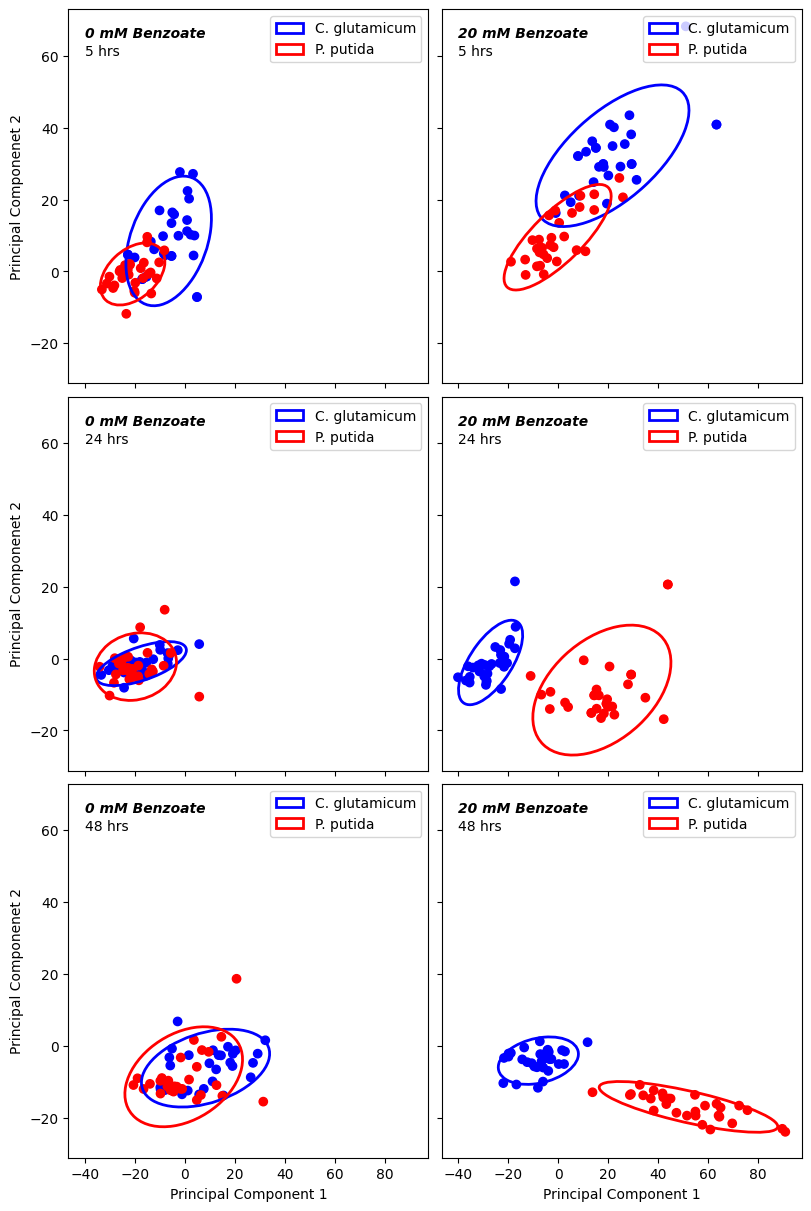

In [16]:
# PC1 vs PC2 for each culture age x condition; points coloured by species (red = P. putida, blue = C. glutamicum)
# with an ellipse per species. Shows how well species separates in the leading PCs.
fig, axs = plt.subplots(3, 2, figsize = (8, 12), sharex = True, sharey = True, constrained_layout = True)
ax = axs.ravel()

inds_list = [inds_5_A, inds_5_C, inds_24_A, inds_24_C, inds_48_A, inds_48_C]
spec_name = ["0 mM Benzoate", "20 mM Benzoate"]
age_name = ["5 hrs", "24 hrs", "48 hrs"]

for i in range(len(inds_list)):
    
    if i >= 4:
        ax[i].set_xlabel("Principal Component 1")
    if i%2 == 0:
        ax[i].set_ylabel('Principal Componenet 2')
    
    X_p = spectral_pca[inds_list[i], :]
    y = bacteria_species[inds_list[i]]
    
    # Colour each point by species: PP (P. putida) = red, CBG (C. glutamicum) = blue
    clist = []
    for j in y:
        if "PP" in j:
            clist.append("red")
        else:
            clist.append("blue")
    
    ax[i].text(-40, 65, spec_name[int(i%2)], fontsize = 10, color = "k", fontstyle = "italic", fontweight = "bold")
    ax[i].text(-40, 60, age_name[int(i/2)], fontsize = 10, color = "k")
   
    cdict = {"CBG": "blue", "PP" : "red"}
    labeldict = {"CBG" : "C. glutamicum" , "PP" : "P. putida"}
    
    sc = ax[i].scatter(X_p[:, 0], X_p[:, 1], c=clist)
    unique_targets = np.unique(y)
    
    for target in unique_targets:
        group = X_p[y == target]
        color = cdict[target]
        labelname = labeldict[target]
        confidence_ellipse_cm(group[:, 0], group[:, 1], ax[i], n_std=2.0, edgecolor=color, linewidth=2, label = labelname)
        
    if i == 1:
        loc = "upper right"
    else:
        loc = "best"
    ax[i].legend(loc = loc)

# PCA weight explanation

Text(0, 0.5, '%Explained variance')

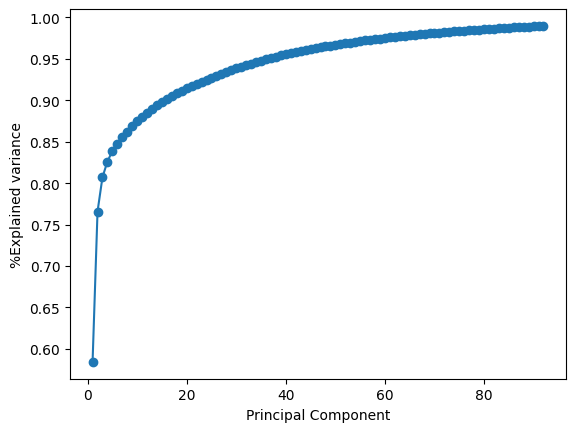

In [17]:
# Explained variance of the global PCA.
# PCA_weights = loadings (rows = PCs, columns = wavenumbers); PCA_variance = cumulative fraction of variance explained.
# Plot the cumulative curve for the first 92 PCs (the upper end of the PC range searched in the classifier notebooks).
PCA_weights = PCA_overall.components_
PCA_variance = np.cumsum(PCA_overall.explained_variance_)/np.sum(PCA_overall.explained_variance_)
plt.plot(range(1, 93), PCA_variance[:92], "-o")
plt.xlabel("Principal Component")
plt.ylabel("%Explained variance")

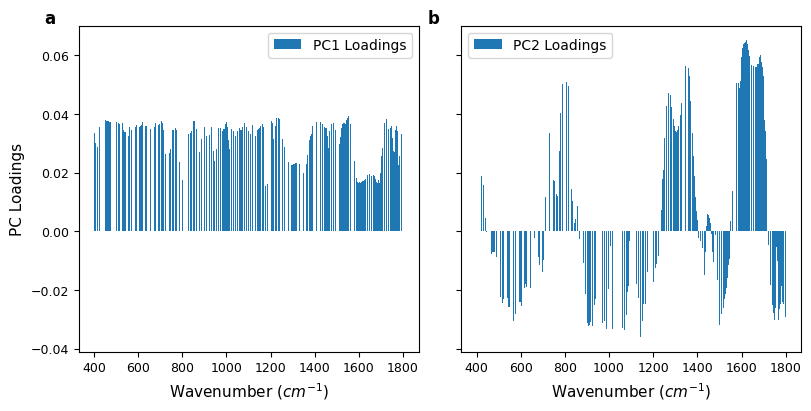

In [18]:
# Fig. S1: loadings of PC1 and PC2 across wavenumber (shows which spectral regions each component weights).
# PC1 loadings are uniformly positive, consistent with an overall scattering/intensity effect (manuscript Section 4.1).
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

fig, axs= plt.subplots(1, 2, figsize = (8, 4), sharex = True, sharey = True, constrained_layout = True)
ax = axs.ravel()

for i in range(len(ax)):
    ax[i].bar(wavenumber, PCA_weights[i,:], label = "PC"+str(i+1)+ " Loadings")
    ax[i].legend()
    ax[i].set_xlabel("Wavenumber ($cm^{-1}$)")

ax[0].set_ylabel("PC Loadings")

fig_cap_labels = ["a", "b"]

axes = [ax[0], ax[1]]
for ax, label in zip(axes, fig_cap_labels):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig("Paper and SI images//Figure_S1.svg", dpi = 600)

In [19]:
# Number of PCs needed to reach 85 %, 90 % and 99 % of the variance (argmax gives the 0-based index of the first PC meeting the
# threshold, i.e. the PC count minus 1). Note the variable named npcs_95 uses the 0.99 threshold.
npcs_85 = np.argmax(PCA_variance >= 0.85)
npcs_90 = np.argmax(PCA_variance >= 0.90)
npcs_95 = np.argmax(PCA_variance >= 0.99)
print(npcs_85, npcs_90, npcs_95)

6 15 92


# Get the OD plots 

In [20]:
# Load the OD600 growth-curve data: dict of condition -> array whose first row is time (h) and the next rows are OD600 per species
with open("OD_data.pkl", "rb") as file:
    OD_loaded_data = pickle.load(file)

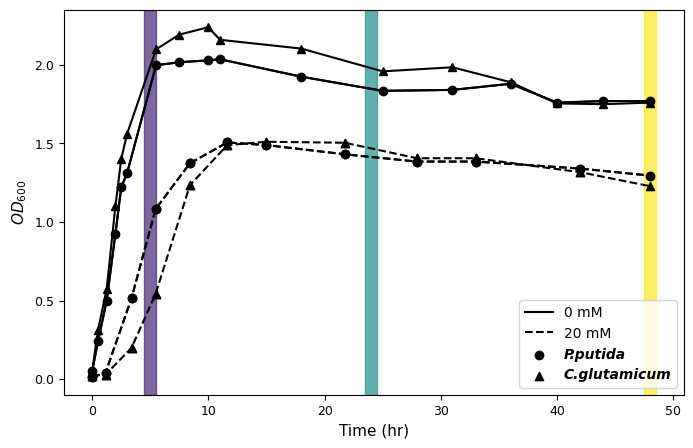

In [21]:
# Growth curves: 0 mM (solid) and 20 mM (dashed) benzoate; circles = P. putida, triangles = C. glutamicum.
# Coloured bands mark the three sampling times (5, 24, 48 h) using the same viridis colours as the PCA plots.
point_markers = ["o", "^"]
line_markers = ["-", "--"]
color_list = ["k", "k"]
name_list = ["P.putida", "C.glutamicum"]
k = 0

plt.figure(figsize = (8, 5))

for i in list(OD_loaded_data.keys()):
    data = OD_loaded_data[i]
    #print(data[0,:])
    plt.plot(data[0,:], data[1,:], line_markers[k], c = "k", label = i)
    
    for j in range(len(data)-1):
        plt.plot(data[0,:], data[j+1,:], line_markers[k]+point_markers[j], color = color_list[j])
        if k == 1:
            plt.scatter(data[0,:], data[j+1,:], marker = point_markers[j], color = color_list[j], label = name_list[j])
    k += 1

cmap = cm.viridis
norm = plt.Normalize(vmin=0, vmax=48)

plt.axvspan(4.5, 5.5, color=cmap(norm(5)), alpha=0.7)
plt.axvspan(23.5, 24.5, color=cmap(norm(24)), alpha=0.7)
plt.axvspan(47.5, 48.5, color=cmap(norm(48)), alpha=0.7)


plt.xlabel("Time (hr)")
plt.ylabel("$OD_{600}$")
leg = plt.legend()
for i, text in enumerate(leg.get_texts()):
    if i > 1:
        text.set_fontstyle('italic')
        text.set_fontweight("bold")

# Image generation for paper

In [22]:
# Inset-axes helper (not used by the figure code below)
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [23]:
# Global font sizes for the publication figures
LABEL_SIZE = 11
TICK_SIZE = 9
PANEL_LABEL_SIZE = 12

plt.rcParams.update({
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
})

C:\Users\slaxminarayan3\AppData\Local\Temp\ipykernel_24936\1625053277.py:124: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('viridis')


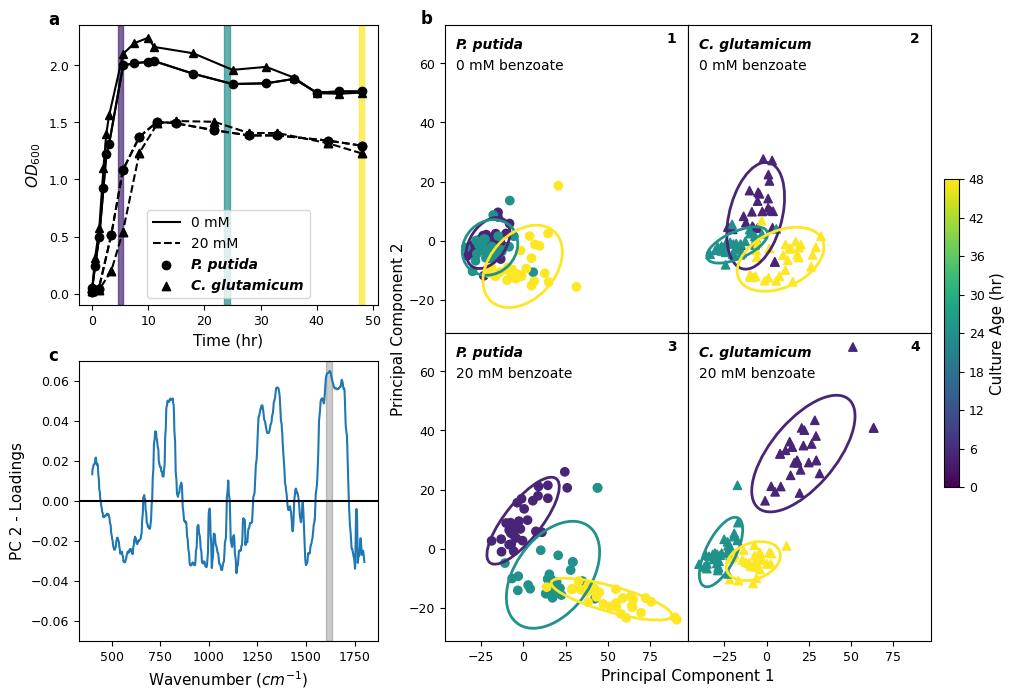

In [24]:
# Fig. 2 (composite): (a) OD600 growth curves with sampling times, (b) PC1 vs PC2 for the four species x condition groups,
# (c) PC2 loadings with the most contributing wavenumber regions shaded. Panel letters: a = top left, c = bottom left, b = right block.
# --- No special imports needed for this version (uses fig.add_axes) ---

fig = plt.figure(figsize=(11, 8))

# OUTER gridspec: left column vs right block
outer = GridSpec(
    2, 2,
    width_ratios=[1.6, 2.6],
    wspace=0.17,
    hspace=0.20
)

ax_left_top = fig.add_subplot(outer[0, 0])
ax_left_bottom = fig.add_subplot(outer[1, 0])

# ================= Left column content (unchanged) =================
# --- Left column, top: OD600 growth curves ---
point_markers = ["o", "^"]
line_markers = ["-", "--"]
color_list = ["red", "blue"]
name_list = ["P. putida", "C. glutamicum"]
k = 0

cmap = cm.viridis
norm = plt.Normalize(vmin=0, vmax=48)

ax_left_top.axvspan(4.5, 5.5, color=cmap(norm(5)), alpha=0.7)
ax_left_top.axvspan(23.5, 24.5, color=cmap(norm(24)), alpha=0.7)
ax_left_top.axvspan(47.5, 48.5, color=cmap(norm(48)), alpha=0.7)

for i in list(OD_loaded_data.keys()):
    data = OD_loaded_data[i]
    ax_left_top.plot(data[0, :], data[1, :], line_markers[k], c="k", label=i)
    for j in range(len(data) - 1):
        ax_left_top.plot(
            data[0, :], data[j + 1, :],
            line_markers[k] + point_markers[j],
            color="k"
        )
        if k == 1:
            ax_left_top.scatter(
                data[0, :], data[j + 1, :],
                marker=point_markers[j],
                color="k",
                label=name_list[j]
            )
    k += 1

leg = ax_left_top.legend()
for i, text in enumerate(leg.get_texts()):
    if i > 1:
        text.set_fontstyle('italic')
        text.set_fontweight("bold")

#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
        
# --- Left column, bottom: PC2 loadings with the most contributing wavenumbers highlighted ---
# Most contributing wavenumbers: z-score of |PC2 loading| across all wavenumbers; those with z >= 2 are shaded.
# (Manuscript Section 3.5 describes this flagging step.)
pc = PCA_weights[1,:]

ax_left_bottom.plot(wavenumber, pc)
ax_left_bottom.axhline(y = 0, color = "k")

abs_pc = abs(pc)
mean_weight = np.mean(abs_pc)
std_weight = np.std(abs_pc)

z_weight = (abs_pc - mean_weight)/std_weight
impact_wv = z_weight >= 2.5

# Find contiguous runs of flagged wavenumbers: +1 in the diff marks a run start, -1 marks the index after a run end
mask = impact_wv
edges = np.diff(impact_wv.astype(int))

start_idx = np.where(edges == 1)[0] + 1
end_idx   = np.where(edges == -1)[0] + 1

# Handle a run that touches the first or last wavenumber
if mask[0]:
    start_idx = np.r_[0, start_idx]

if mask[-1]:
    end_idx = np.r_[end_idx, len(y)]

# Shade each contiguous region
for s, e in zip(start_idx, end_idx):
    ax_left_bottom.axvspan(wavenumber[s], wavenumber[e-1], alpha=0.2, color='k')


ax_left_top.set_ylabel("$OD_{600}$")
ax_left_top.set_xlabel("Time (hr)")
ax_left_bottom.set_ylabel("PC 2 - Loadings")
ax_left_bottom.set_xlabel(r"Wavenumber ($cm^{-1}$)")
ax_left_bottom.set_ylim(-0.07, 0.07)

# ================= Right block layout =================
# Single cell for the scatter grid (no dedicated cbar column needed)
right_outer = outer[:, 1].subgridspec(1, 1, wspace=0.0, hspace=0.0)

scatter_gs = right_outer[0, 0].subgridspec(
    2, 2,
    wspace=0.00,  # no horizontal gap between the two scatter columns
    hspace=0.00   # stacked rows touch
)

# Scatter axes
ax_r1 = fig.add_subplot(scatter_gs[0, 0])
ax_r2 = fig.add_subplot(scatter_gs[0, 1], sharex=ax_r1, sharey=ax_r1)  # (panel 2)
ax_r3 = fig.add_subplot(scatter_gs[1, 0], sharex=ax_r1, sharey=ax_r1)
ax_r4 = fig.add_subplot(scatter_gs[1, 1], sharex=ax_r1, sharey=ax_r1)  # (panel 4)

# Ticks: show only outer ticks to avoid clutter
ax_r1.tick_params(bottom=False, labelbottom=False)
ax_r2.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)
ax_r4.tick_params(left=False, labelleft=False)

# --- Right block: PC1 vs PC2 scatter plots (panels 1-4: P. putida 0 mM, C. glutamicum 0 mM, P. putida 20 mM, C. glutamicum 20 mM) ---
# ================= Plot content (unchanged) =================
inds_list   = [inds_P_A, inds_C_A, inds_P_C, inds_C_C]
ax_list     = [ax_r1, ax_r2, ax_r3, ax_r4]
spec_name   = ["P. putida", "C. glutamicum"]
cond_name   = ["0 mM benzoate", "20 mM benzoate"]
marker_list = ["o", "^", "o", "^"]

sc = None
for i in range(len(inds_list)):
    X_p = spectral_pca[inds_list[i], :]
    y = culture_age[inds_list[i]]

    cmap = cm.get_cmap('viridis')
    norm = plt.Normalize(vmin=0, vmax=max(y))

    ax_list[i].text(-40, 65, spec_name[int(i % 2)],
                    fontsize=10, color="k", fontstyle="italic", fontweight="bold")
    ax_list[i].text(-40, 58, cond_name[int(i / 2)], fontsize=10, color="k")
    ax_list[i].text(85, 67, str(i + 1), fontsize=10, color="k", fontweight="bold")

    sc = ax_list[i].scatter(X_p[:, 0], X_p[:, 1], c=y, cmap=cmap, norm=norm, marker=marker_list[i])

    unique_targets = np.unique(y)
    for target in unique_targets:
        group = X_p[y == target]
        color = cmap(norm(target))
        confidence_ellipse_cm(group[:, 0], group[:, 1], ax_list[i],
                              n_std=2.0, edgecolor=color, linewidth=2)

# ================= Colorbar: centered in right column,
#     spanning from mid of panel 2 to mid of panel 4 =================
# Get figure-coordinates positions of panels 2 and 4
bbox_r2 = ax_r2.get_position()  # top-right panel
bbox_r4 = ax_r4.get_position()  # bottom-right panel

# Midpoints (y) of each panel
y_mid_r2 = 0.5 * (bbox_r2.y0 + bbox_r2.y1)
y_mid_r4 = 0.5 * (bbox_r4.y0 + bbox_r4.y1)

# Colorbar height: from middle of 4 up to middle of 2
cbar_bottom = y_mid_r4
cbar_height = y_mid_r2 - y_mid_r4

# Horizontal placement: just to the right of the right column
pad = 0.012  # gap between panel 2/4 and the colorbar (figure fraction)
# Keep a similar thickness to your previous bar (tied to panel width)
bar_width = (bbox_r2.x1 - bbox_r2.x0) * 0.06  # ~6% of a scatter panel width
cbar_left = bbox_r2.x1 + pad

# Create the free-floating colorbar axis
cax = fig.add_axes([cbar_left, cbar_bottom, bar_width, cbar_height])

cb = fig.colorbar(sc, cax=cax, label="Culture Age (hr)")
cb.set_ticks([0, 6, 12, 18, 24, 30, 36, 42, 48])
cb.ax.tick_params(labelsize=9)  # optional

# ================= Shared labels for the right block =================
right_axes = (ax_r1, ax_r2, ax_r3, ax_r4)
right_left  = min(ax.get_position().x0 for ax in right_axes)
right_right = max(ax.get_position().x1 for ax in right_axes)
x_center = (right_left + right_right) / 2.0

fig.text(x_center, 0.06, "Principal Component 1", ha="center", fontsize=11)
fig.text(right_left - 0.035, 0.5, "Principal Component 2",
         va="center", ha="right", rotation="vertical", fontsize=11)

# Panel letters (a = growth curves, c = loadings, b = scatter grid) and save the figure
# ------------------- Panel Labels -------------------
fig_cap_labels = ["a", "c", "b"]
axes = [ax_left_top, ax_left_bottom, ax_r1]
for ax, label in zip(axes, fig_cap_labels):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold", va="top")

plt.savefig(r"Paper and SI images//Figure_2.svg")